<a href="https://colab.research.google.com/github/esrakonya/gunes_enerjisi_tahmini/blob/main/gunes_enerjisi_tahmini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine
## Günlük Güneş Enerjisi Tahmini: Hava Bilgilerinden Güneş Radyasyonuna

**Ad Soyad:** Esra Konya  |  **Tarih:** Ekim 2026
**Araçlar:** Python, Google Colab, Pandas, NumPy, Matplotlib, scikit-learn

---
# Aşama 1: Problem Tanımı ve Proje Planı

## Proje Tanım Formu

| Alan | İçerik |
|---|---|
| **Proje adı** | Günlük Güneş Enerjisi Tahmini: Hava Bilgilerinden Güneş Radyasyonuna |
| **İlgi alanı** | Enerji ve çevre |
| **Problem cümlesi** | Bir günün sıcaklık, nem, bulutluluk ve ay bilgisinden o günün güneş radyasyonunu (kWh/m²/gün) tahmin et. |
| **Hedef değişken (y)** | `ALLSKY_SFC_SW_DWN` (günlük güneş radyasyonu) |
| **Özellikler (X)** | Sıcaklık (`T2M`), bağıl nem (`RH2M`), bulutluluk (`CLOUD_AMT`), ay (`month`) |
| **Problem türü** | Regresyon (hedef sürekli bir sayı) |
| **Veri kaynağı** | NASA POWER, Marmaris (Muğla) konumu (36.85 enlem, 28.27 boylam), 1 Ocak – 31 Aralık 2025, günlük |
| **Model** | LinearRegression |

## Neden Bu Konuyu Seçtim?

Günlük hayatımızdan bir şeyi yapay zekaya tahmin ettirmek istedim. Güneş paneli düşünen kişiler için günlük güneş enerjisi tahmininin faydalı olabileceğini düşündüm. Veri olarak NASA'nın hava ile ilgili verilerinden yararlandım.

## Gerekçe

Güneş paneli kurmayı düşünen bir ev sahibi, çatısına bir günde ne kadar güneş enerjisi düşeceğini bilmek ister. Bu bilgi, panelin ne kadar elektrik üreteceğini kabaca planlamaya ve yatırımın değerini değerlendirmeye yardımcı olur. Bu projede, kolay elde edilen hava bilgilerinden (sıcaklık, nem, bulutluluk ve ay) günlük güneş radyasyonunu tahmin eden bir model geliştirdim. Hangi hava koşullarının güneş enerjisini en çok etkilediğini görmek, hem bireysel kullanıcılar hem de yenilenebilir enerji planlaması için anlamlı bir içgörü sağlar.

**Not:** Model "yarın ne kadar güneş olacak?" sorusunu değil, "bu hava koşullarında ne kadar güneş düşer?" sorusunu cevaplar. Hava tahmin servislerinden gelen değerlerle birleştirilirse ileriye dönük planlamada kullanılabilir.

---
# Aşama 2: Veri Toplama ve Hazırlama

Veri NASA POWER servisinden indirilip `gunes_verisi.csv` olarak kaydedilir ve `pd.read_csv` ile okunur. NASA eksik ölçümleri `-999` ile işaretlediği için bu değerler eksik değere (`NaN`) çevrilir.

In [ ]:
import requests
import pandas as pd

# Marmaris (Muğla) koordinatları
lat, lon = 36.85, 28.27

# NASA POWER günlük veri adresi: 2025 yılı, 5 parametre, CSV formatı
url = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
    "?parameters=ALLSKY_SFC_SW_DWN,T2M,RH2M,CLOUD_AMT,WS2M"
    f"&community=RE&longitude={lon}&latitude={lat}"
    "&start=20250101&end=20251231&format=CSV"
)

# Veriyi indir, açıklama satırlarını atla (başlık satırı "YEAR" ile başlar)
raws = requests.get(url).text.splitlines()
header = next(i for i, s in enumerate(raws) if s.startswith("YEAR"))

# CSV dosyası olarak kaydet
with open("gunes_verisi.csv", "w") as f:
    f.write("\n".join(raws[header:]))

# CSV'yi Pandas ile oku, -999 değerlerini eksik değere çevir
df = pd.read_csv("gunes_verisi.csv")
df = df.replace(-999, float("nan"))

# Boyut, sütun adları ve sütun başına eksik değer sayısı
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())

(365, 8)
['YEAR', 'MO', 'DY', 'ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'CLOUD_AMT', 'WS2M']
YEAR                 0
MO                   0
DY                   0
ALLSKY_SFC_SW_DWN    0
T2M                  0
RH2M                 0
CLOUD_AMT            0
WS2M                 0
dtype: int64


In [ ]:
# Ay bilgisini 'month' adıyla özellik olarak hazırla
df["month"] = df["MO"]

# Kopya satır sayısı (0 beklenir) ve mantıksız değer kontrolü
print(df.duplicated().sum())
df = df.dropna()   # eksik değer yok, satır sayısı değişmedi
print(df.shape)
print(df.describe())
df.head()

0
(365, 9)
         YEAR          MO          DY  ALLSKY_SFC_SW_DWN         T2M  \
count   365.0  365.000000  365.000000         365.000000  365.000000   
mean   2025.0    6.526027   15.720548           5.192903   18.897507   
std       0.0    3.452584    8.808321           2.224545    7.705468   
min    2025.0    1.000000    1.000000           0.495400    2.010000   
25%    2025.0    4.000000    8.000000           3.187200   12.430000   
50%    2025.0    7.000000   16.000000           5.300600   17.830000   
75%    2025.0   10.000000   23.000000           7.285000   26.850000   
max    2025.0   12.000000   31.000000           8.708900   35.300000   

             RH2M   CLOUD_AMT        WS2M       month  
count  365.000000  365.000000  365.000000  365.000000  
mean    64.269205   27.758110    2.568192    6.526027  
std     16.740475   29.022505    1.124332    3.452584  
min     25.440000    0.390000    0.890000    1.000000  
25%     51.280000    3.910000    1.820000    4.000000  
50% 

,YEAR,MO,DY,ALLSKY_SFC_SW_DWN,T2M,RH2M,CLOUD_AMT,WS2M,month
0,2025,1,1,2.9306,9.98,71.09,14.79,1.12,1
1,2025,1,2,2.4518,10.93,79.21,37.45,1.11,1
2,2025,1,3,1.2763,11.03,86.79,88.28,1.87,1
3,2025,1,4,0.6446,11.58,92.99,99.93,1.77,1
4,2025,1,5,2.6345,11.49,84.01,45.21,2.44,1


## Veri Sözlüğü

| Sütun | Tip | Anlamı | Rol |
|---|---|---|---|
| `YEAR` | Sayısal | Yıl (2025) | Modelde kullanılmaz |
| `MO` / `month` | Sayısal (1-12) | Ay | Özellik (X), kodda `month` adıyla |
| `DY` | Sayısal (1-31) | Ayın günü | Modelde kullanılmaz |
| `T2M` | Sayısal | 2 m yükseklikte ortalama sıcaklık (°C) | Özellik (X) |
| `RH2M` | Sayısal | 2 m yükseklikte bağıl nem (%) | Özellik (X) |
| `CLOUD_AMT` | Sayısal | Bulut örtüsü oranı (%) | Özellik (X) |
| `WS2M` | Sayısal | 2 m yükseklikte rüzgar hızı (m/s) | Modelde kullanılmaz (hedefle neredeyse ilişkisiz) |
| `ALLSKY_SFC_SW_DWN` | Sayısal | Yüzeye ulaşan günlük güneş radyasyonu (kWh/m²/gün) | Hedef (y) |

Tüm sütunlar sayısaldır, kategorik sütun yoktur. Veri, tek bir istasyonun ölçümü değil, yaklaşık 50 km çözünürlüklü bir model ızgarasının değeridir.

## Temizleme Adımları

1. NASA POWER eksik ölçümleri `-999` ile işaretlediği için `replace(-999, nan)` ile bu değerleri eksik değere çevirdim.
2. `df.isnull().sum()` ile eksik değerleri kontrol ettim. 8 sütunun hepsinde 0 eksik değer çıktı, bu yüzden `dropna` veya `fillna` kullanmam gerekmedi.
3. `df.duplicated().sum()` ile kopya satır aradım, sonuç 0 çıktı.
4. `describe()` ile mantıksız değer kontrolü yaptım: negatif radyasyon yok, nem ve bulutluluk 0-100 aralığında, sıcaklık makul (2.01 – 35.30 °C).
5. `MO` sütununu `month` adıyla özellik olarak kullandım. `YEAR`, `DY` ve `WS2M` modelde kullanılmadı.

**Sonuç:** 365 satır, 4 özellik sütunu, 1 hedef sütun.

---
# Aşama 3: Keşifçi Veri Analizi (EDA) ve Görselleştirme

In [ ]:
# Veriyi tanı: boyut, ilk satırlar ve kullandığımız sütunların özet istatistiği
print("Boyut:", df.shape)
print(df.head())
print(df[["T2M", "RH2M", "CLOUD_AMT", "month", "ALLSKY_SFC_SW_DWN"]].describe())

# Her ayda kaç günlük kayıt var?
print(df["month"].value_counts().sort_index())

Boyut: (365, 9)
   YEAR  MO  DY  ALLSKY_SFC_SW_DWN    T2M   RH2M  CLOUD_AMT  WS2M  month
0  2025   1   1             2.9306   9.98  71.09      14.79  1.12      1
1  2025   1   2             2.4518  10.93  79.21      37.45  1.11      1
2  2025   1   3             1.2763  11.03  86.79      88.28  1.87      1
3  2025   1   4             0.6446  11.58  92.99      99.93  1.77      1
4  2025   1   5             2.6345  11.49  84.01      45.21  2.44      1
              T2M        RH2M   CLOUD_AMT       month  ALLSKY_SFC_SW_DWN
count  365.000000  365.000000  365.000000  365.000000         365.000000
mean    18.897507   64.269205   27.758110    6.526027           5.192903
std      7.705468   16.740475   29.022505    3.452584           2.224545
min      2.010000   25.440000    0.390000    1.000000           0.495400
25%     12.430000   51.280000    3.910000    4.000000           3.187200
50%     17.830000   66.620000   14.040000    7.000000           5.300600
75%     26.850000   78.120000   52.

month
1     2.473613
2     3.765225
3     4.832577
4     5.836310
5     6.851490
6     8.148113
7     7.971142
8     7.146948
9     5.945147
10    4.029384
11    2.892303
12    2.350558
Name: ALLSKY_SFC_SW_DWN, dtype: float64
           mean     min     max
month                          
1      2.473613  0.6446  3.6456
2      3.765225  1.6591  5.1415
3      4.832577  1.1669  6.4742
4      5.836310  1.7532  7.4081
5      6.851490  1.7707  8.3940
6      8.148113  7.2542  8.7089
7      7.971142  7.3474  8.5906
8      7.146948  6.6521  7.7028
9      5.945147  2.7120  6.7373
10     4.029384  1.8293  5.4742
11     2.892303  0.7051  3.7862
12     2.350558  0.4954  3.0960
T2M                  0.692502
RH2M                -0.744984
CLOUD_AMT           -0.705168
WS2M                 0.050994
month               -0.078044
ALLSKY_SFC_SW_DWN    1.000000
Name: ALLSKY_SFC_SW_DWN, dtype: float64


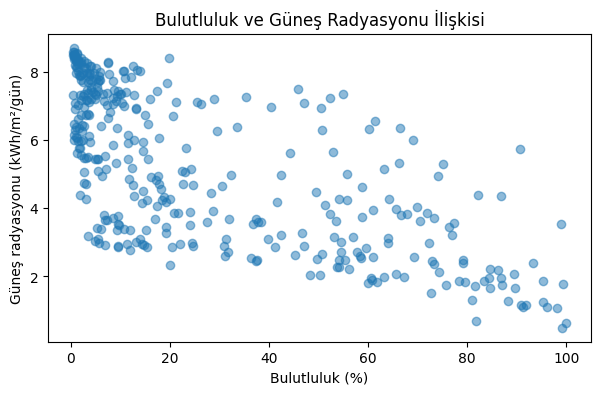

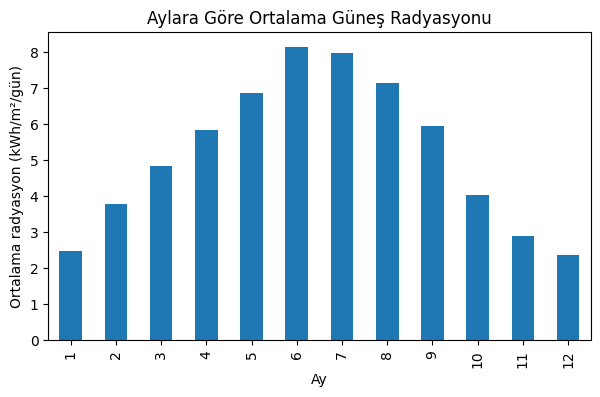

In [ ]:
import matplotlib.pyplot as plt

# Aya göre ortalama güneş radyasyonu
monthly = df.groupby("month")["ALLSKY_SFC_SW_DWN"].mean()
print(monthly)

# Aylara göre radyasyonun ortalaması, en düşüğü ve en yükseği
print(df.groupby("month")["ALLSKY_SFC_SW_DWN"].agg(["mean", "min", "max"]))

# Özelliklerin hedefle korelasyonu
print(df[["T2M", "RH2M", "CLOUD_AMT", "WS2M", "month", "ALLSKY_SFC_SW_DWN"]].corr()["ALLSKY_SFC_SW_DWN"])

# Grafik 1: Bulutluluk - radyasyon ilişkisi (dağılım grafiği)
plt.figure(figsize=(7, 4))
plt.scatter(df["CLOUD_AMT"], df["ALLSKY_SFC_SW_DWN"], alpha=0.5)
plt.title("Bulutluluk ve Güneş Radyasyonu İlişkisi")
plt.xlabel("Bulutluluk (%)")
plt.ylabel("Güneş radyasyonu (kWh/m²/gün)")
plt.show()

# Grafik 2: Aylık ortalama radyasyon (çubuk grafik)
plt.figure(figsize=(7, 4))
monthly.plot(kind="bar")
plt.title("Aylara Göre Ortalama Güneş Radyasyonu")
plt.xlabel("Ay")
plt.ylabel("Ortalama radyasyon (kWh/m²/gün)")
plt.show()

## Grafik Yorumları

**Genel gözlemim:** Grafikler genel olarak beklediğim gibi çıktı. Yaz aylarında sıcaklık yüksek, nem ve bulutluluk düşük olduğu için ortalama güneş radyasyonu daha yüksek, kış aylarında ise bunun tersi koşullar nedeniyle daha düşük çıkıyor. Mevsimin kendisi de (gün uzunluğu ve güneşin geliş açısı) bu farkta etkili olabilir.

**Grafik 1 (dağılım):** Bulutluluk arttıkça güneş radyasyonu genel olarak düşüyor. Noktalar sol üstten sağ alta doğru iniyor. Ancak bulutluluğun düşük olduğu (%0-20) günlerde bile radyasyon yaklaşık 2.5 ile 8.7 arasında çok geniş dağılıyor. Bu, bulutluluğun tek başına yeterli olmadığını, mevsimin (güneşin geliş açısı ve gün uzunluğu) de büyük etkisi olduğunu gösteriyor.

**Grafik 2 (çubuk):** Radyasyon yıl içinde tek tepeli bir desen izliyor: Ocak'ta düşük, Haziran'da zirve (8.15), Aralık'ta tekrar düşük (2.35). Yaz zirvesi kış dibinin yaklaşık 3,5 katı.

## Keşif Bulguları

1. **Belirgin mevsimsellik var.** Aylık ortalama Haziran'da en yüksek (8.15), Aralık'ta en düşük (2.35 kWh/m²/gün). Yaz aylarında günlük radyasyon birbirine yakınken (Haziran'da 7.25 – 8.71), ilkbahar ve sonbaharda aynı ay içinde bile büyük farklar var (Mart'ta 1.17 – 6.47).
2. **Nem, hedefle en güçlü ilişkiye sahip özellik** (korelasyon -0.74). Nem arttıkça radyasyon düşüyor.
3. **Bulutluluk da güçlü negatif ilişkili** (-0.71). Bulut arttıkça yüzeye ulaşan güneş enerjisi azalıyor.
4. **Sıcaklık pozitif ilişkili** (+0.69). Güneşli günler daha sıcak oluyor.
5. **Rüzgar hızı neredeyse etkisiz** (+0.05), bu yüzden modele alınmadı. `month` korelasyonu da sıfıra yakın (-0.08), çünkü ay ile radyasyon arasındaki ilişki doğrusal değil, ters U şeklinde. Korelasyon yalnızca doğrusal ilişkiyi ölçtüğü için bu deseni yakalayamıyor.

---
# Aşama 4: Model Kurma ve Eğitme

## Model Seçim Gerekçesi

Hedef değişken (günlük güneş radyasyonu) sürekli bir sayı olduğu için bu bir regresyon problemidir. Nem, bulutluluk ve sıcaklığın hedefle belirgin bir ilişkisi olduğu için basit ve yorumlanabilir olan `LinearRegression` uygun bir başlangıç modelidir. Katsayılara bakarak her özelliğin etkisinin yönünü açıklayabiliriz.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Özellikler (X) ve hedef (y)
features = ["T2M", "RH2M", "CLOUD_AMT", "month"]
X = df[features]
y = df["ALLSKY_SFC_SW_DWN"]

# %80 eğitim, %20 test. random_state sabit: her çalıştırmada aynı bölünme
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Eğitim:", X_train.shape, "Test:", X_test.shape)

# Modeli eğitim verisiyle eğit
model = LinearRegression()
model.fit(X_train, y_train)

# R² skoru: 1'e yakın olması iyi. Eğitim ve test yakınsa ezberleme yok
print("Eğitim R²:", model.score(X_train, y_train))
print("Test R²:", model.score(X_test, y_test))

Eğitim: (292, 4) Test: (73, 4)
Eğitim R²: 0.7724914533077464
Test R²: 0.7068077700377267


**Bölünme:** 365 satırın 292'si eğitime, 73'ü teste ayrıldı.

---
# Aşama 5: Tahmin ve Değerlendirme

In [ ]:
import pandas as pd
from sklearn.metrics import mean_absolute_error

# 1) Test verisinde tahmin yap ve ortalama mutlak hatayı (MAE) ölç
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print("Ortalama mutlak hata (MAE):", round(mae, 2), "kWh/m²/gün")
print("Hedefin ortalaması:", round(y.mean(), 2))

# 2) Katsayılar: her özelliğin etkisinin yönü
print(dict(zip(features, model.coef_.round(3))))

# 3) Modelin hiç görmediği 3 yeni örnek için tahmin
new = pd.DataFrame({
    "T2M": [30, 15, 8],
    "RH2M": [35, 60, 80],
    "CLOUD_AMT": [5, 40, 90],
    "month": [7, 4, 12],
})
new["prediction"] = model.predict(new[features]).round(2)
print(new)

# 4) 'month' özelliğinin katkısını görmek için month'suz model ile karşılaştır
features2 = ["T2M", "RH2M", "CLOUD_AMT"]
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    df[features2], y, test_size=0.2, random_state=42
)
model2 = LinearRegression().fit(X_train2, y_train2)
print("month'suz Test R²:", model2.score(X_test2, y_test2))
print("month'lu  Test R²:", model.score(X_test, y_test))

Ortalama mutlak hata (MAE): 0.94 kWh/m²/gün
Hedefin ortalaması: 5.19
{'T2M': np.float64(0.126), 'RH2M': np.float64(-0.026), 'CLOUD_AMT': np.float64(-0.032), 'month': np.float64(-0.219)}
   T2M  RH2M  CLOUD_AMT  month  prediction
0   30    35          5      7        8.03
1   15    60         40      4        5.04
2    8    80         90     12        0.30
month'suz Test R²: 0.6349926893699175
month'lu  Test R²: 0.7068077700377267


## Başarı Puanı ve Yorumu

- **Test R² = 0.71:** Model, günlük radyasyondaki değişimin yaklaşık %71'ini açıklıyor.
- **MAE = 0.94 kWh/m²/gün:** Ortalama hedefin (5.19) yaklaşık %18'i kadar sapma var.
- **Eğitim R² (0.77) ile test R² (0.71) yakın:** Ciddi bir aşırı öğrenme görünmüyor.
- **`month` özelliğinin katkısı:** Ay çıkarılınca test R² 0.63'e düşüyor, eklenince 0.71 oluyor. Sıcaklık güneşe biraz gecikmeli tepki verdiği için aynı sıcaklıkta sonbahar günü ilkbahar gününden daha az güneş alıyor olabilir ve ay bu farkı düzeltiyor olabilir. Bu bir yorumdur, kanıtlanmış bir sonuç değil.
- **Katsayılar:** Sıcaklık pozitif (+0.126), nem (-0.026), bulutluluk (-0.032) ve ay (-0.219) negatif. Birimler farklı olduğu için katsayı büyüklükleri doğrudan kıyaslanamaz, yalnızca yönleri yorumlanır. Yönler EDA bulgularıyla tutarlı.

## Tahmin Tablosu (girdi → tahmin)

| Sıcaklık (°C) | Nem (%) | Bulutluluk (%) | Ay | Tahmin (kWh/m²/gün) | Yorum |
|---|---|---|---|---|---|
| 30 | 35 | 5 | Temmuz | 8.03 | Güneşli yaz günü, verideki üst sınıra (8.71) yakın, mantıklı |
| 15 | 60 | 40 | Nisan | 5.04 | Parçalı bulutlu, orta düzey, mantıklı |
| 8 | 80 | 90 | Aralık | 0.30 | Kapalı kış günü, yön doğru ama gözlenen minimumun (0.50) altında |

## Değerlendirme Notu: Model güvenilir mi?

**Kendi yorumum:** Dürüst olmak gerekirse tahmin daha iyi olabilirdi. Ay bilgisi bu tahmin için doğrusal bir özellik olmadığından, sonucu bir miktar değiştirmiş olabileceğini düşünüyorum.

Model, genel eğilimi iyi yakalıyor ancak tek tek günlerde yaklaşık 1 kWh/m² sapabiliyor. Bu yüzden **kaba planlama için kullanılabilir, kesin üretim hesabı için güvenilir değildir.** Eğitim ve test skorlarının yakın olması nedeniyle aşırı öğrenme riski düşüktür. Düşük kalan skorun asıl nedeni modelin yetersiz kalmasıdır (underfitting): ilişkilerin bir kısmı doğrusal değildir.

**Zayıf yönler:**
1. Ay sayısal olarak kullanıldığı için Aralık (12) ile Ocak (1) komşuluğu ve yıllık döngü modellenemiyor. Radyasyon yıl içinde ters U şeklinde değişiyor, doğrusal model bunu düz çizgi olarak kullanıyor.
2. Doğrusal model uç girdilerde gerçekçi aralığın dışında tahmin üretebiliyor (örneğin 0.30).
3. Veri tek yıl ve tek konumdan geliyor ve model ızgarasından geldiği için istasyon ölçümü değil.
4. Günler rastgele bölündüğü için komşu günler hem eğitimde hem testte yer alıyor, bu yüzden test skoru biraz iyimser olabilir.
5. Test seti küçük (73 satır), farklı bölünmelerde R² değeri değişebilir.
6. Sıcaklık, nem ve bulutluluk birbiriyle kısmen ilişkili olabilir.

**Olası iyileştirmeler (denenmedi, gelecek çalışma):** Ayı sin/cos ile döngüsel bir özelliğe çevirmek, karar ağacı gibi doğrusal olmayan bir model denemek, birden fazla yıl veya konum eklemek.

---
# Aşama 6: Akıllı Tahmin Aracı (Mini Uygulama)

`predict_solar()` fonksiyonu kullanıcıdan sıcaklık, nem, bulutluluk ve ay değerlerini alır, modelden tahmin üretir ve sonucu bir cümleyle yazdırır. Model negatif radyasyon üretebileceği için sonuç `max(0, ...)` ile sınırlandı. Mesaj eşikleri verinin çeyreklerine göre ayarlandı (%25 = 3.19, %75 = 7.29).

Hücreyi çalıştırınca altında bir kutucuk açılır. Değeri yazıp Enter'a basın (ondalık için nokta kullanın, ay tam sayı olmalı).

In [ ]:
def predict_solar():
    # Kullanıcıdan girdileri al
    temp = float(input("Ortalama sıcaklık (°C): "))
    humidity = float(input("Bağıl nem (%): "))
    cloud = float(input("Bulutluluk (%): "))
    month = int(input("Ay (1-12): "))

    # Girdiyi modelin beklediği tablo biçimine çevir ve tahmin üret
    x_new = pd.DataFrame([[temp, humidity, cloud, month]], columns=features)
    result = max(0, model.predict(x_new)[0])   # negatif sonucu 0'a sabitle

    # Sonucu anlamlı bir cümleyle yazdır
    print(f"\nBu koşullarda günlük güneş radyasyonu yaklaşık {result:.2f} kWh/m² olacak.")
    if result >= 7.3:
        print("Panel verimi için çok iyi bir gün.")
    elif result >= 3.2:
        print("Orta düzeyde bir güneş enerjisi günü.")
    else:
        print("Düşük güneş enerjisi bekleniyor.")

# Örnek A: kapalı kış günü (8, 80, 90, 12)
predict_solar()

Ortalama sıcaklık (°C): 8
Bağıl nem (%): 80
Bulutluluk (%): 90
Ay (1-12): 12

Bu koşullarda günlük güneş radyasyonu yaklaşık 0.30 kWh/m² olacak.
Düşük güneş enerjisi bekleniyor.


In [ ]:
# Örnek B: güneşli yaz günü (28, 30, 7, 8 gir)
predict_solar()

Ortalama sıcaklık (°C): 28
Bağıl nem (%): 30
Bulutluluk (%): 7
Ay (1-12): 8

Bu koşullarda günlük güneş radyasyonu yaklaşık 7.62 kWh/m² olacak.
Panel verimi için çok iyi bir gün.


## Örnek Çalıştırmalar

| Girdi (sıcaklık, nem, bulut, ay) | Çıktı |
|---|---|
| 28, 30, 7, 8 | Yaklaşık 7.62 kWh/m². Panel verimi için çok iyi bir gün. |
| 8, 80, 90, 12 | Yaklaşık 0.30 kWh/m². Düşük güneş enerjisi bekleniyor. |

İkinci sonuç, değerlendirme notundaki zayıf yönün somut örneğidir: model gözlenen minimumun (0.50) altında bir değer üretiyor.

---
# Sonuç ve Çıkarım

Bu projede NASA POWER verisiyle (Marmaris, 2025, 365 gün) sıcaklık, nem, bulutluluk ve aydan günlük güneş radyasyonunu tahmin eden bir `LinearRegression` modeli kurdum. Model test verisinde R² = 0.71 ve MAE = 0.94 kWh/m²/gün elde etti, ciddi bir aşırı öğrenme görünmedi. En güçlü ilişkiler nem, bulutluluk ve sıcaklıkla bulundu, ay bilgisi ise doğrusal olmayan etkisine rağmen skora katkı yaptı. Model kaba planlama için uygundur. Ayı döngüsel hale getirmek, doğrusal olmayan modeller denemek ve daha çok yıl/konum eklemek ileride sonuçları iyileştirebilir.

**Bu projeden ne öğrendim:** Bu proje bana, yapay zeka tahminlerinin hangi aşamalardan geçilerek sonuca ulaşıldığını gözlemleme ve deneyimleme fırsatı verdi ve büyük katkı sağladı.
